In [ ]:
import numpy as np
import tf_keras

# Load CIFAR-10 using tf_keras
(X_train, y_train), (X_test, y_test) = tf_keras.datasets.cifar10.load_data(cache_dir=None)

# Normalize pixel values between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("Data loaded successfully!")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

170498071/170498071 [==============================] - 2836s 17us/step
Data loaded successfully!
Training shape: (50000, 32, 32, 3)
Testing shape: (10000, 32, 32, 3)


In [ ]:
import tf_keras as keras
from tf_keras import layers, models

# Model 1: CNN with Max Pooling
def make_pooled_model():
    return models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3), name='conv1'),
        layers.MaxPooling2D((2, 2), name='pool1'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2'),
        layers.MaxPooling2D((2, 2), name='pool2'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='last_conv'),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="CNN_With_Pooling")

# Model 2: CNN without Max Pooling (uses strided convs)
def make_unpooled_model():
    return models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3), name='conv1'),
        layers.Conv2D(32, (3, 3), strides=(2, 2), activation='relu', padding='same', name='stride1'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2'),
        layers.Conv2D(64, (3, 3), strides=(2, 2), activation='relu', padding='same', name='stride2'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='last_conv'),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="CNN_Without_Pooling")

model_pool = make_pooled_model()
model_no_pool = make_unpooled_model()

# Model Summaries
print("=== Model 1: With Pooling ===")
model_pool.summary()

print("\n=== Model 2: Without Pooling ===")
model_no_pool.summary()

=== Model 1: With Pooling ===
Model: "CNN_With_Pooling"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1 (Conv2D)              (None, 32, 32, 32)        896       
                                                                 
 pool1 (MaxPooling2D)        (None, 16, 16, 32)        0         
                                                                 
 conv2 (Conv2D)              (None, 16, 16, 64)        18496     
                                                                 
 pool2 (MaxPooling2D)        (None, 8, 8, 64)          0         
                                                                 
 last_conv (Conv2D)          (None, 8, 8, 64)          36928     
                                                                 
 flatten (Flatten)           (None, 4096)              0         
                                                                 
 dense (Dense)      

In [ ]:
EPOCHS = 5
BATCH_SIZE = 32

model_pool.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_no_pool.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train Model 1
print("--- Training Model WITH Pooling ---")
hist_pool = model_pool.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, y_test)
)

# Train Model 2
print("\n--- Training Model WITHOUT Pooling ---")
hist_no_pool = model_no_pool.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, y_test)
)

--- Training Model WITH Pooling ---
Epoch 1/5
1563/1563 [==============================] - 120s 74ms/step - loss: 1.4374 - accuracy: 0.4787 - val_loss: 1.1492 - val_accuracy: 0.5918
Epoch 2/5
1563/1563 [==============================] - 126s 80ms/step - loss: 1.0039 - accuracy: 0.6480 - val_loss: 0.9263 - val_accuracy: 0.6796
Epoch 3/5
1563/1563 [==============================] - 115s 73ms/step - loss: 0.8415 - accuracy: 0.7060 - val_loss: 0.8431 - val_accuracy: 0.7032
Epoch 4/5
1563/1563 [==============================] - 110s 70ms/step - loss: 0.7390 - accuracy: 0.7404 - val_loss: 0.8467 - val_accuracy: 0.7105
Epoch 5/5
1563/1563 [==============================] - 115s 73ms/step - loss: 0.6575 - accuracy: 0.7688 - val_loss: 0.8438 - val_accuracy: 0.7106

--- Training Model WITHOUT Pooling ---
Epoch 1/5
1563/1563 [==============================] - 148s 94ms/step - loss: 1.5178 - accuracy: 0.4464 - val_loss: 1.2174 - val_accuracy: 0.5584
Epoch 2/5
1563/1563 [===========================

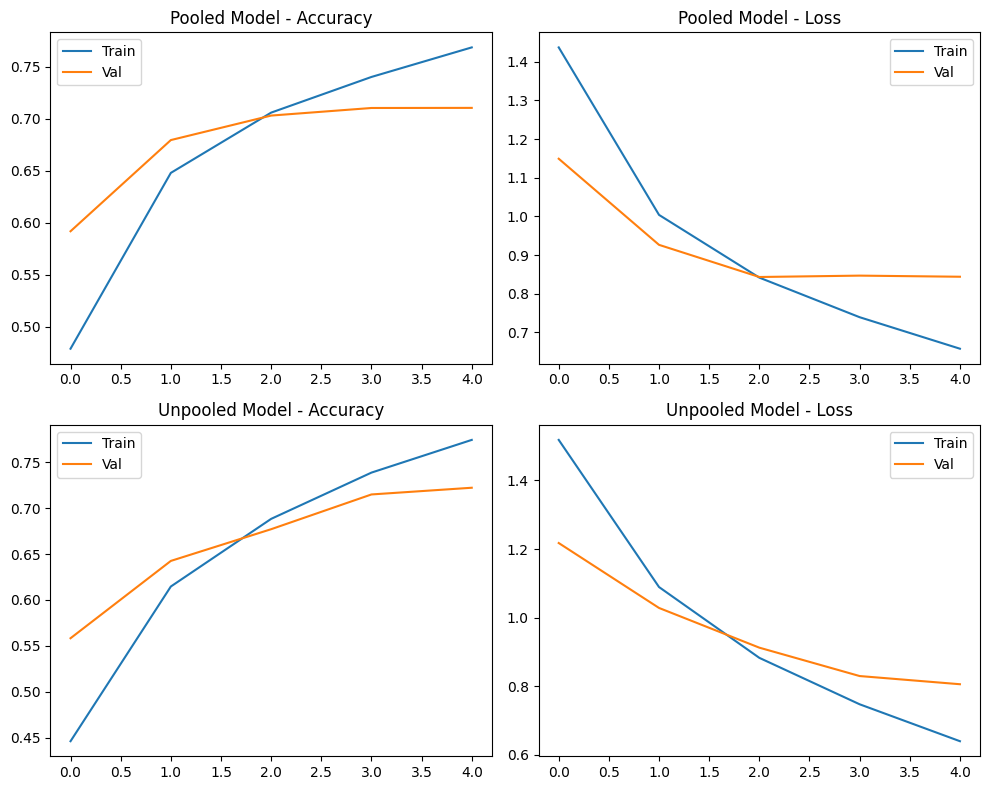

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Pooled model plots
axes[0, 0].plot(hist_pool.history['accuracy'], label='Train')
axes[0, 0].plot(hist_pool.history['val_accuracy'], label='Val')
axes[0, 0].set_title('Pooled Model - Accuracy')
axes[0, 0].legend()

axes[0, 1].plot(hist_pool.history['loss'], label='Train')
axes[0, 1].plot(hist_pool.history['val_loss'], label='Val')
axes[0, 1].set_title('Pooled Model - Loss')
axes[0, 1].legend()

# Unpooled model plots
axes[1, 0].plot(hist_no_pool.history['accuracy'], label='Train')
axes[1, 0].plot(hist_no_pool.history['val_accuracy'], label='Val')
axes[1, 0].set_title('Unpooled Model - Accuracy')
axes[1, 0].legend()

axes[1, 1].plot(hist_no_pool.history['loss'], label='Train')
axes[1, 1].plot(hist_no_pool.history['val_loss'], label='Val')
axes[1, 1].set_title('Unpooled Model - Loss')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

Generating Grad-CAM Visualizations...


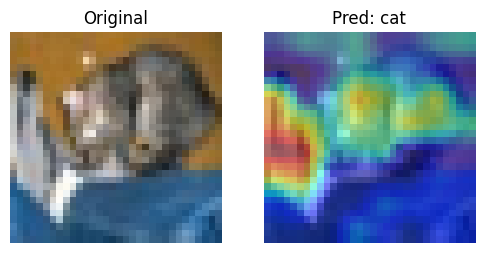

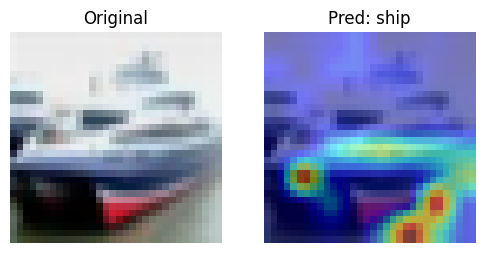

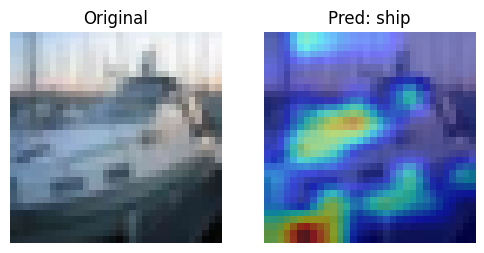

In [ ]:
import tensorflow as tf

def make_gradcam(model, img, layer_name='last_conv'):
    img_tensor = np.expand_dims(img, axis=0)

    grad_model = tf_keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_output, preds = grad_model(img_tensor)
        top_class = tf.argmax(preds[0])
        class_channel = preds[:, top_class]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def plot_prediction(model, img):
    img_tensor = np.expand_dims(img, axis=0)
    pred_idx = np.argmax(model.predict(img_tensor, verbose=0))
    pred_name = class_names[pred_idx]

    cam = make_gradcam(model, img)
    cam_resized = tf.image.resize(cam[..., np.newaxis], (32, 32)).numpy().squeeze()

    fig, ax = plt.subplots(1, 2, figsize=(6, 3))
    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[0].axis('off')

    ax[1].imshow(img)
    ax[1].imshow(cam_resized, cmap='jet', alpha=0.5)
    ax[1].set_title(f"Pred: {pred_name}")
    ax[1].axis('off')
    plt.show()

# Show Grad-CAM outputs for 3 test images
print("Generating Grad-CAM Visualizations...")
for idx in [0, 1, 2]:
    plot_prediction(model_pool, X_test[idx])